[![Mở trong Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thanhmk/kinhteluong/blob/main/KTL%20T%C3%A0i%20ch%C3%ADnh/Module_4/B2_Mo_hinh_chuoi_thoi_gian.ipynb)

In [ ]:
# Chuẩn bị môi trường trên Colab (chạy ô này một lần trước khi chạy các ô khác)
import os, urllib.request, urllib.parse

BASE = "https://raw.githubusercontent.com/thanhmk/kinhteluong/main/KTL%20T%C3%A0i%20ch%C3%ADnh/Module_4/"
FILES = ['M4. dxy_r_data.csv', 'M4. goog_eur_10.csv']
for f in FILES:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + urllib.parse.quote(f), f)
        print("Đã tải:", f)

## KINH TẾ LƯỢNG TÀI CHÍNH
MODULE 4 | BÀI 2

---

# **CÁC MÔ HÌNH THỐNG KÊ CHUỖI THỜI GIAN**

|  |  |
|:---|:---|
|**Thời gian đọc** | 60 phút |
|**Kiến thức nền** | Phân tích hồi quy, thống kê cơ bản  |
|**Từ khóa** |  Sai phân bậc nhất, toán tử lùi (backshift), nhiễu trắng, bước ngẫu nhiên, bước ngẫu nhiên có độ trôi, trung bình trượt|


---

*Trong bài này, trước tiên ta sẽ tiếp nối bài trước để giới thiệu một số phương pháp loại bỏ xu hướng khỏi chuỗi thời gian không dừng. Sau đó, ta sẽ giới thiệu một số mô hình chuỗi thời gian. Đó là các mô hình chuỗi thời gian nền tảng giúp người đọc hiểu các mô hình chuỗi thời gian phức tạp hơn sẽ được giới thiệu ở các bài và module sau. Cụ thể, ta sẽ đề cập nhiễu trắng, bước ngẫu nhiên, bước ngẫu nhiên có độ trôi và các mô hình trung bình trượt. Ta sẽ tính trung bình và phương sai của chúng cũng như ACF và PACF. Ta cũng sẽ kiểm tra tính dừng của chúng.*

In [16]:
# Tải thư viện
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.arima_process import arma_generate_sample

plt.rcParams["figure.figsize"] = (16, 9)  # Kích thước hình

In [17]:
# Tải bộ dữ liệu
m4_data = pd.read_csv("M4. goog_eur_10.csv")
dxyr_data = pd.read_csv("M4. dxy_r_data.csv")

# Chuyển biến ngày sang định dạng ngày
m4_data["Date2"] = pd.to_datetime(m4_data["Date"], format="%m/%d/%Y")
dxyr_data["Date2"] = pd.to_datetime(dxyr_data["Date"], format="%m/%d/%Y")

# Chọn cột
goog = m4_data.loc[:, ["Date2", "GOOGLE"]].set_index("Date2")

## **1. Loại bỏ xu hướng khỏi chuỗi thời gian không dừng**

Ở bài trước, ta đã thấy một trong những điểm chính của phân tích chuỗi thời gian là hiểu quan hệ của các quan sát dữ liệu ở các thời điểm khác nhau trong một chuỗi thời gian. Ta đã giới thiệu ACF và PACF là các chỉ số then chốt để hiểu quan hệ giữa các quan sát trong một chuỗi thời gian. Ta cũng đã giới thiệu chuỗi thời gian dừng. Chuỗi thời gian dừng nghĩa là trung bình và tự hiệp phương sai của nó độc lập với vị trí thời gian tuyệt đối của các quan sát dữ liệu. Ví dụ, $Cov(X_t, X_s)$ phải chỉ phụ thuộc vào chênh lệch $t-s$. Ước lượng ACF và PACF sẽ chính xác và ổn định mà không phải lo ta chọn đoạn dữ liệu nào để ước lượng. Do đó, điều then chốt là có được chuỗi thời gian dừng trước khi làm công việc mô hình hóa.

Loại bỏ xu hướng khỏi chuỗi thời gian không dừng thường là bước đầu tiên để xử lý dữ liệu chuỗi thời gian. Trong phần này, ta sẽ đi qua hai phương pháp phổ biến để loại bỏ xu hướng: dùng biến xu hướng hoặc lấy sai phân. Ta sẽ dùng cổ phiếu Google làm ví dụ để minh họa quy trình.

### **1.1 Loại bỏ xu hướng bằng biến xu hướng**

Phương pháp đầu tiên để loại bỏ xu hướng khỏi chuỗi thời gian không dừng là mô hình hóa biến với một biến xu hướng tuyến tính. Hình 1 cho thấy khái niệm biến xu hướng tuyến tính, một đường thẳng theo thời gian trong đồ thị.

**Hình 1: Một biến xu hướng**

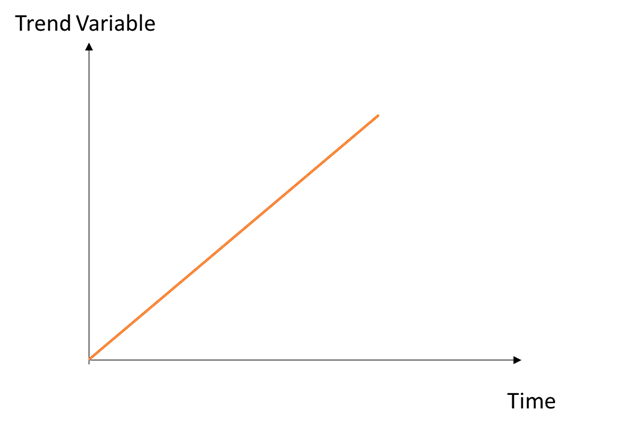

Bây giờ, ta có thể chạy một mô hình hồi quy đơn giản cho giá cổ phiếu Google như sau:

$$ \text{Giá cổ phiếu Google} = \text{hệ số chặn} + \beta \cdot \text{xu hướng} $$

Hình 2 bên dưới cho thấy kết quả mô hình.

**Hình 2: Mô hình hồi quy cho giá cổ phiếu Google và xu hướng**

In [18]:
# Loại bỏ xu hướng
timeTrend = np.linspace(1, len(goog.GOOGLE), len(goog.GOOGLE))
timeTrend = sm.add_constant(timeTrend)

# Ước lượng OLS
model = sm.OLS(goog.GOOGLE, timeTrend)
fit_g = model.fit()
fit_g.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 GOOGLE   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     4956.
Date:                Wed, 04 Jun 2025   Prob (F-statistic):               0.00
Time:                        10:00:08   Log-Likelihood:                -10671.
No. Observations:                1505   AIC:                         2.135e+04
Df Residuals:                    1503   BIC:                         2.136e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        413.4033     14.988     27.583      0.000     384.004     442.802
x1             1.2136      0.017     70.396      0.000       1.180       1.247
==============================================================================
Omnibus:                      101.043   Durbin-Watson:                   0.006
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              120.227
Skew:                           0.678   Prob(JB):                     7.82e-27
Kurtosis:                       3.277   Cond. No.                     1.74e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.74e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Tiếp theo, hãy vẽ phần dư từ mô hình theo thời gian trong đồ thị sau.

**Hình 3: Phần dư từ hồi quy đơn giản của giá cổ phiếu Google theo xu hướng**

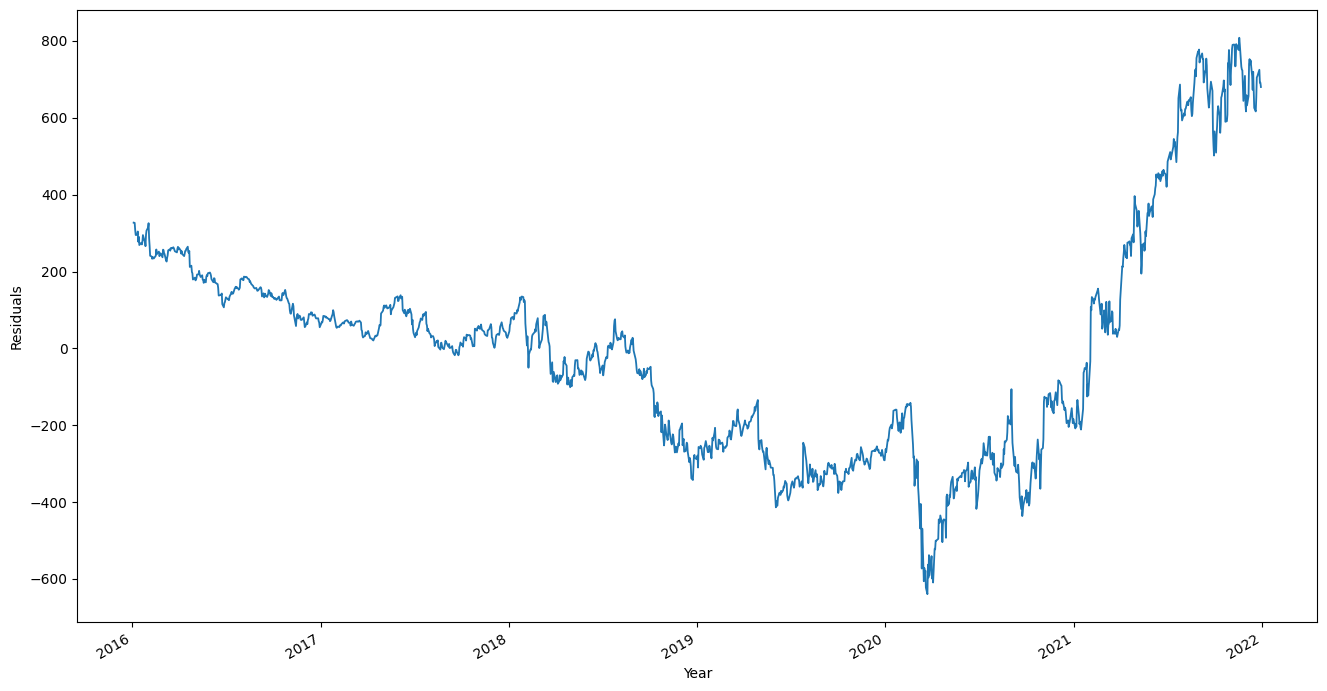

In [19]:
# Vẽ phần dư
goog_res = fit_g.resid
goog_res.plot(linewidth=1.3, xlabel="Năm", ylabel="Phần dư")
plt.show()

Từ hình 3, ta thấy phần dư từ mô hình hồi quy đơn giản với biến xu hướng không có vẻ thể hiện tính dừng. Chuỗi thời gian của phần dư cho thấy cái giống một "dạng chữ V", và do đó, có vẻ trung bình không không đổi theo thời gian. Như vậy, phần dư từ hồi quy không tạo thành chuỗi thời gian dừng.

Thêm biến xu hướng có vẻ không đủ để biến giá cổ phiếu Google thành chuỗi thời gian dừng.

Hãy xem phương pháp lấy sai phân.

### **2.2 Loại bỏ xu hướng bằng phương pháp lấy sai phân**

Một phương pháp phổ biến khác để loại bỏ xu hướng trong chuỗi thời gian là lấy sai phân. Trước khi đi vào chi tiết lấy sai phân, hãy định nghĩa một số thuật ngữ.

#### **2.2.1 Ký hiệu**

Ký hiệu đầu tiên ta sẽ giới thiệu là sai phân bậc nhất. Sai phân bậc nhất được định nghĩa là:

$$ \nabla x_{t} = x_{t} - x_{t-1} $$

Và sai phân bậc hai có thể viết là:

$$ \nabla^{2} x_{t} = \nabla (\nabla x_t) = \nabla(x_{t}-x_{t-1}) = (x_{t}-x_{t-1}) - (x_{t-1}-x_{t-2}) $$

Ký hiệu tiếp theo là toán tử lùi (backshift operator). Toán tử lùi được định nghĩa là:

$$ B x_{t} = x_{t-1} $$

Và

$$ B^{2} x_{t} = B (B x_{t}) = B x_{t-1} = x_{t-2} $$

Từ trên, ta có thể viết toán tử lùi tổng quát như sau:

$$ B^{k} x_{t} = x_{t-k} $$

Với toán tử lùi, ta cũng có thể viết sai phân bậc nhất bằng toán tử lùi:

$$ \nabla x_{t} = x_{t}-x_{t-1} = x_{t}-Bx_{t} = (1-B)x_{t} $$

Khi đó, sai phân bậc hai có thể được định nghĩa và viết như sau:

$$ \nabla ^{2} x_{t} = (1-B)^{2} x_{t} = (1-2B+B^{2}) x_{t} = x_{t} - 2 x_{t-1} + x_{t-2} $$

Và sai phân bậc $d$ có thể được định nghĩa là:

$$ \nabla^{d} = (1-B)^{d} $$

#### **2.2.2. Phương pháp lấy sai phân**

Phương pháp lấy sai phân được dùng để tạo chuỗi thời gian sai phân bậc nhất. Hãy tiếp tục dùng giá cổ phiếu Google làm ví dụ. Hình 4 cho thấy sai phân bậc nhất của giá cổ phiếu Google.

**Hình 4: Sai phân bậc nhất của giá cổ phiếu Google**

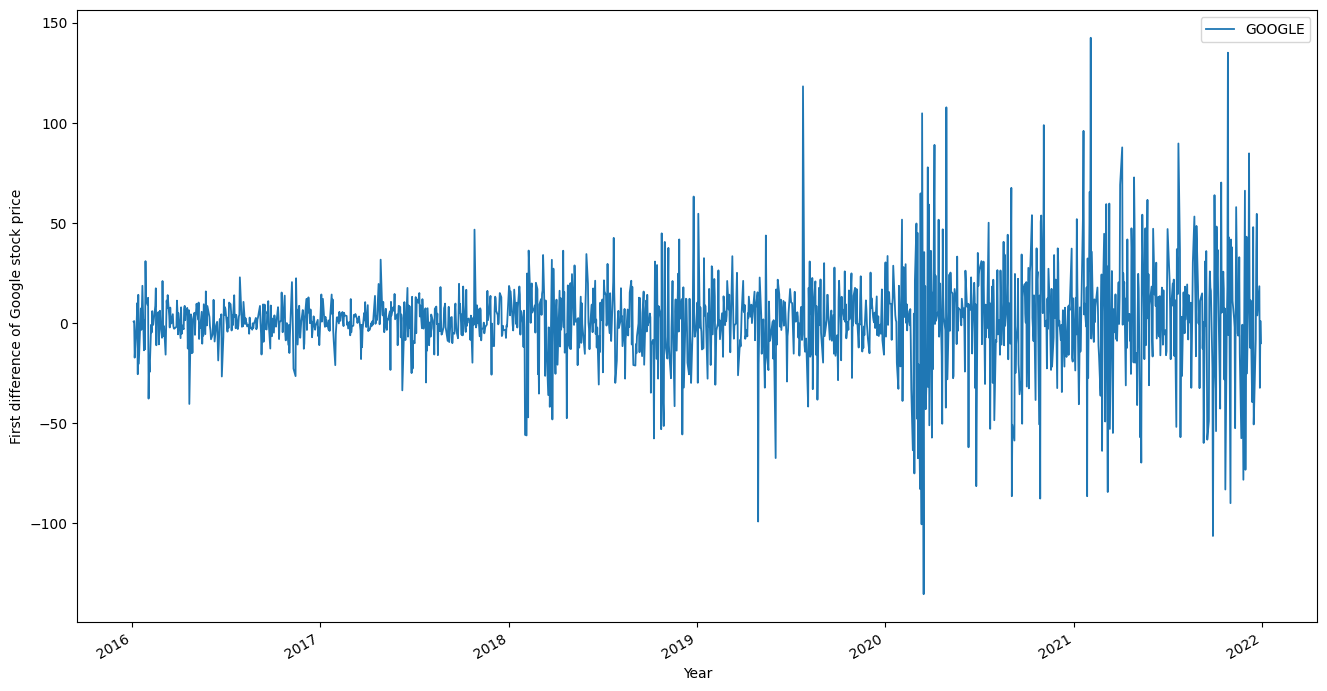

In [20]:
# Vẽ sai phân bậc nhất của giá cổ phiếu Google
goog.diff().plot(
    linewidth=1.3, xlabel="Năm", ylabel="Sai phân bậc nhất của giá cổ phiếu Google"
)
plt.show()

Ta thấy sai phân bậc nhất của giá cổ phiếu Google dao động quanh $0$ trong suốt giai đoạn. Tuy nhiên, biến thiên của sai phân bậc nhất tăng lên theo thời gian. Điều đó nghĩa là phương sai phụ thuộc vào thời gian. Do đó, sai phân bậc nhất của giá cổ phiếu Google vẫn chưa đủ để làm nó dừng. Hãy xem ACF của nó.

**Hình 5: ACF của sai phân bậc nhất của giá cổ phiếu Google**

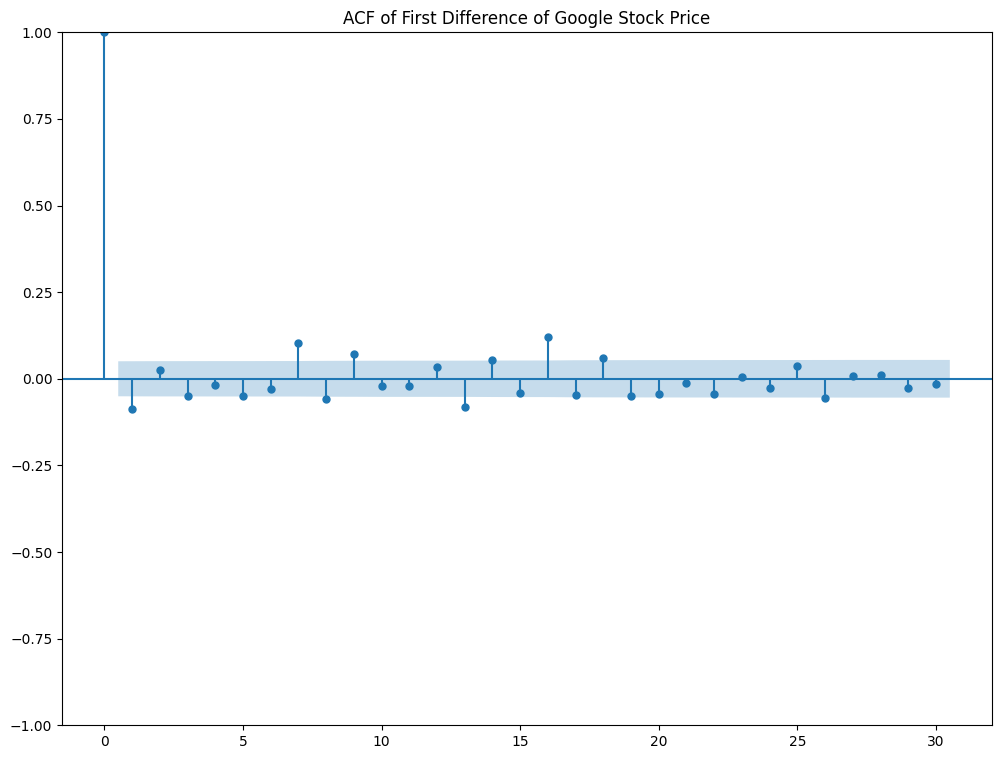

In [21]:
# ACF của sai phân bậc nhất của giá cổ phiếu Google
# (Lưu ý: [1:] vì ta cần bỏ phần tử đầu tiên do mô hình mất một điểm dữ liệu)
fig, ax = plt.subplots(figsize=(12, 9))
sm.graphics.tsa.plot_acf(
    goog.diff()[1:],
    title="ACF của sai phân bậc nhất của giá cổ phiếu Google",
    lags=30,
    ax=ax,
)
plt.show()

Từ hình 5, ta thấy có một vài độ trễ trước độ trễ 16 có ý nghĩa ở mức 95%. Ta có thể dùng thông tin này cho việc mô hình hóa về sau.

Ta đã dùng cả hai phương pháp biến xu hướng và lấy sai phân để loại bỏ xu hướng cho chuỗi thời gian giá cổ phiếu Google. Đáng tiếc, không phương pháp nào làm tốt việc chuyển chuỗi thời gian thành chuỗi dừng. Ở các phần sau, ta sẽ học thêm các mô hình để xem chúng có phải lựa chọn mô hình tốt hơn cho giá cổ phiếu Google không.

## **3. Nhiễu trắng (White Noise)**

**Nhiễu trắng** là một mô hình chuỗi thời gian đặc biệt. Chuỗi thời gian nhiễu trắng được tạo từ một tập hợp các biến ngẫu nhiên không tương quan. Ta có thể định nghĩa chuỗi thời gian nhiễu trắng ${W_{t}}$ như sau:

$$ {W_{t}}\sim WN(0,\sigma^{2}) $$

Tự hiệp phương sai của nó được cho bởi:

$$ \gamma_{_{W}}(h) = \begin{cases}
  \sigma_{2}  & \text{ với }  h=0 \\
  0  &  \text{ với } |h| \gt 0
\end{cases} $$

Vì cả trung bình và tự hiệp phương sai của nhiễu trắng đều độc lập với $t$, nhiễu trắng là chuỗi thời gian dừng.

Nếu các biến ngẫu nhiên nhiễu trắng cũng độc lập và cùng phân phối, ta có thể ký hiệu nó như sau:

$$ {W_{t}} \sim iid(0,\sigma^{2}) $$

Nếu mọi biến ngẫu nhiên đều i.i.d. và có phân phối chuẩn, đây là chuỗi thời gian nhiễu trắng chuẩn và ta có thể ký hiệu nó như sau:

$$ {W_{t}} \sim iid N(0,\sigma^{2}) $$

Hãy tạo một mô phỏng của quá trình nhiễu trắng (xem hình 6).

**Hình 6: Ví dụ chuỗi thời gian nhiễu trắng chuẩn**

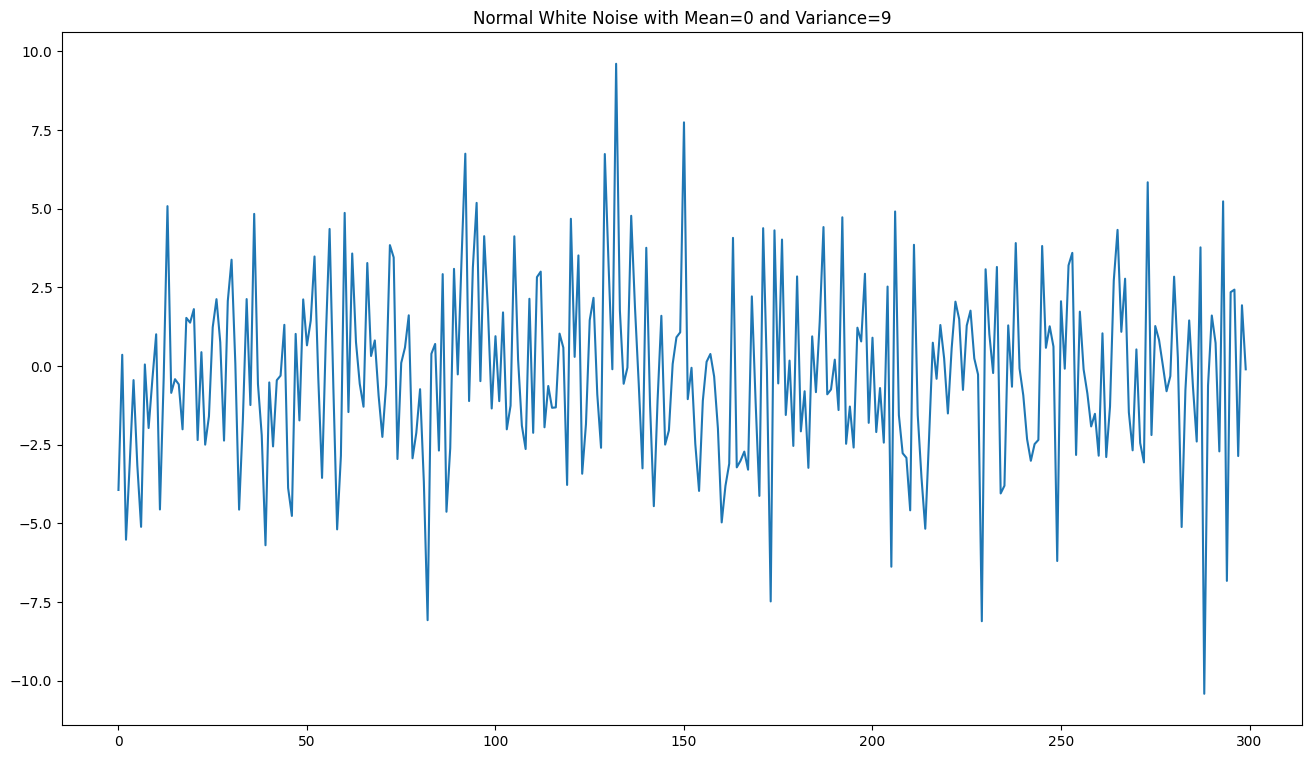

In [22]:
# Ví dụ chuỗi thời gian nhiễu trắng chuẩn
plt.plot(np.random.normal(0, 3, 300))
plt.title("Nhiễu trắng chuẩn với trung bình=0 và phương sai=9")
plt.show()

Hình 6 cho thấy chuỗi thời gian nhiễu trắng với trung bình = $0$ và phương sai = $9$. Ta thấy chuỗi thời gian khá lởm chởm, nhưng nó dao động quanh $0$.

Nhiễu trắng chuẩn độc lập tương tự các số hạng sai số chuẩn độc lập trong hồi quy OLS. Thường thì một chuỗi thời gian có thể được phân rã thành thành phần xu hướng, thành phần mùa vụ và thành phần phần dư. Nếu ta có thể mô hình hóa phần dư bằng mô hình nhiễu trắng, ta sẽ có thể mô hình hóa toàn bộ chuỗi thời gian và dự báo nó. Bản chất ngẫu nhiên của nhiễu trắng làm nó là lựa chọn tốt cho số hạng ngẫu nhiên trong các mô hình chuỗi thời gian tiếp theo.

## **4. Bước ngẫu nhiên (Random Walk)**

Mô hình chuỗi thời gian tiếp theo ta muốn nói đến là chuỗi thời gian bước ngẫu nhiên. Chuỗi thời gian bước ngẫu nhiên nói rằng giá trị hiện tại chỉ phụ thuộc vào giá trị quá khứ cộng một thành phần ngẫu nhiên. Ta có thể viết định nghĩa toán học như sau:

Nếu $\{ X_{t} \}$ là chuỗi thời gian bước ngẫu nhiên và $x_0 = 0$ thì $X_{t} = X_{t-1} + W_{t}$ trong đó ${W_{t}} \sim WN(0,\sigma^{2})$

Từ định nghĩa trên, bạn có thể thay $X_{t-1}$ bằng $X_{t-2} + W_{t-1}$ và tiếp tục quy trình thay thế tương tự cho đến khi $X$ được biểu diễn bằng $W_{i}$ trong đó $i = 1, \cdots, t$ và $ X_{0}$. Ta gọi đây là kỹ thuật thế ngược. Sau khi làm quy trình này, bạn có thể thay định nghĩa trên bằng công thức sau:

$$ X_{t} = \sum_{i=1}^{t} W_{i} + X_{0} = \sum_{i=1}^{t} W_{i} $$

Hàm trung bình:

$$  E(X_{t}) = E(X_{t-1} + W_{t}) = E(\sum_{i=1}^{t} W_{i} + X_{0}) = X_{0}=0 $$

Từ hàm trung bình, ta biết nó không phụ thuộc vào $t$ mà phụ thuộc vào thời điểm đầu tiên $X_{0}$. Trong trường hợp này, nó là $0$.

Tự hiệp phương sai:

$$ COV(X_{t+h},X_{t}) = COV(X_{t} + W_{t+1} + W_{t+2} + \cdots + W_{t+h}, X_{t}) = Cov(X_{t},X_{t}) = t \sigma^{2} $$

Ta thấy tự hiệp phương sai phụ thuộc vào $t$. Do đó, chuỗi thời gian bước ngẫu nhiên không phải là chuỗi thời gian dừng.

**Hình 7: Các ví dụ bước ngẫu nhiên**

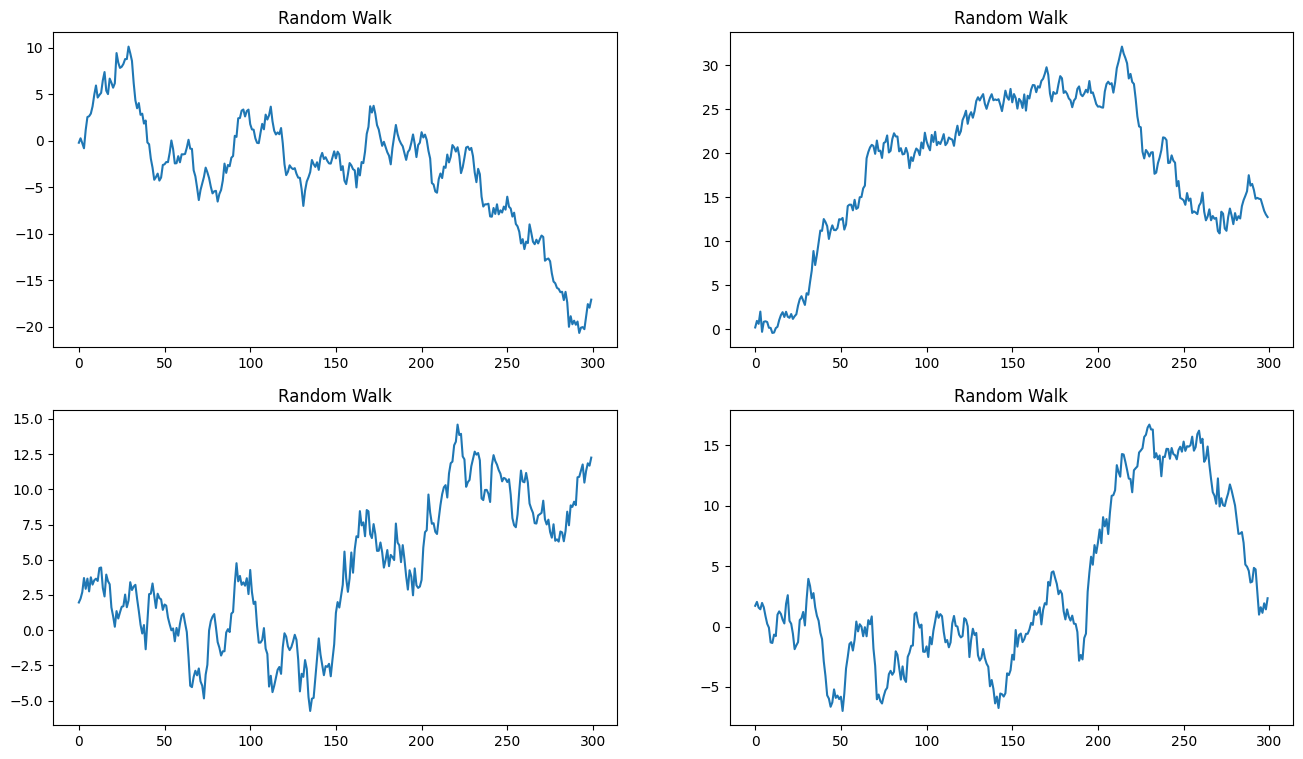

In [23]:
# Bốn bước ngẫu nhiên


# Hàm hỗ trợ
def RandWalkPlot(seed):
    np.random.seed(seed)
    wn = np.random.normal(0, 1, 300)
    rw = np.cumsum(wn)
    plt.plot(rw)
    plt.title("Bước ngẫu nhiên")


# 4 ví dụ bước ngẫu nhiên
ax1 = plt.subplot(221)
RandWalkPlot(12345)  # Ví dụ bước ngẫu nhiên 1

ax2 = plt.subplot(222)
RandWalkPlot(54321)  # Ví dụ bước ngẫu nhiên 2

ax3 = plt.subplot(223)
RandWalkPlot(222)  # Ví dụ bước ngẫu nhiên 3

ax4 = plt.subplot(224)
RandWalkPlot(333)  # Ví dụ bước ngẫu nhiên 4
plt.show()

Ở hình 7, ta mô phỏng bốn chuỗi thời gian bước ngẫu nhiên gồm 300 điểm dữ liệu với cùng thiết lập: nhiễu trắng chuẩn và $X_{0}=0$. Mỗi lần ta tạo một chuỗi thời gian từ cùng mô hình bước ngẫu nhiên, ta sẽ có một chuỗi thời gian bước ngẫu nhiên rất khác. Không có mẫu chung rõ ràng. Ta cũng thấy bước ngẫu nhiên không bị giới hạn trong một khoảng như chuỗi thời gian dừng.

Một biến thể phổ biến của chuỗi thời gian bước ngẫu nhiên là **bước ngẫu nhiên có độ trôi (random walk with a drift)**. Bước ngẫu nhiên có độ trôi là thêm một số hạng hằng số $D$ vào mô hình bước ngẫu nhiên. Ta có thể viết mô hình bước ngẫu nhiên có độ trôi như sau:

Nếu $\{ X_t \}$ là chuỗi thời gian bước ngẫu nhiên có độ trôi và $x_{0} = 0$ thì $X_{t} = D + X_{t-1} + W_{t}$ trong đó ${W_{t}} \sim WN(0,\sigma^{2})$ và $D$ là hằng số

Ta gọi $D$ là độ trôi. Với kỹ thuật thế ngược, ta có thể viết lại mô hình như sau:

$$ X_{t} = D t + \sum_{i=1}^{t} W_{i}+X_{0} = D t +\sum_{i=1}^{t} W_{i} $$

Hàm trung bình:

$$ E(X_{t}) = D t + \sum_{i=1}^{t} E(W_{i}) = D t $$

Từ hàm trung bình, ta thấy nó phụ thuộc vào t.

Tự hiệp phương sai:

$$ COV(X_{t+h},X_{t}) = COV(X_{t} + W_{t+1} + W_{t+2} + \cdots + W_{t+h}, X_{t}) = Cov(X_{t},X_{t}) = t \sigma^{2} $$

Vì sự khác biệt giữa bước ngẫu nhiên và bước ngẫu nhiên có độ trôi chỉ là việc thêm một độ trôi hằng số, tự hiệp phương sai của chúng phải như nhau. Ta thấy bước ngẫu nhiên có độ trôi cũng không phải là chuỗi thời gian dừng. Cả trung bình và tự hiệp phương sai đều phụ thuộc vào $t$. Ngoài ra, do có thêm độ trôi, trung bình tăng khi thời gian tăng. Do đó, bước ngẫu nhiên có độ trôi là một lựa chọn để mô hình hóa các chuỗi thời gian thực tế có dạng xu hướng.

**Hình 8: Ví dụ bước ngẫu nhiên có độ trôi dương và bước ngẫu nhiên có độ trôi âm**

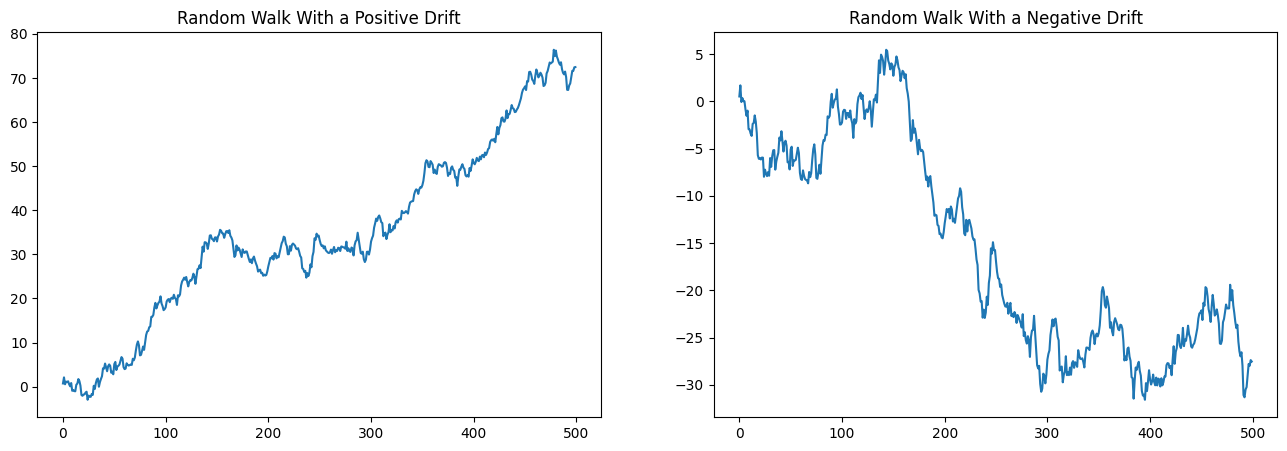

In [24]:
# Ví dụ bước ngẫu nhiên có độ trôi
np.random.seed(99999)
wnd = np.random.normal(0, 1, 500)

plt.figure(figsize=(16, 5))
ax1 = plt.subplot(121)
plt.plot(np.cumsum(wnd + 0.1))
plt.title("Bước ngẫu nhiên có độ trôi dương")

ax2 = plt.subplot(122)
plt.plot(np.cumsum(wnd - 0.1))
plt.title("Bước ngẫu nhiên có độ trôi âm")
plt.show()

Ở hình 8, ta tạo một chuỗi thời gian bước ngẫu nhiên có độ trôi dương và một chuỗi thời gian bước ngẫu nhiên có độ trôi âm. Ta thấy chuỗi thời gian độ trôi dương có xu hướng đi lên rõ ràng như kỳ vọng. Chuỗi thời gian độ trôi âm ban đầu đi lên rồi từ từ đi xuống nhưng dạng rất lởm chởm. Từ các đồ thị trên, bước ngẫu nhiên có độ trôi có thể là lựa chọn mô hình cho chuỗi thời gian có dạng xu hướng.

## **5. Trung bình trượt (Moving Average)**

Mô hình trung bình trượt cố gắng mô hình hóa một cú sốc có tác động trong một khung thời gian hữu hạn. Nếu một cú sốc quan tâm có tác động ban đầu và tác động dần mất đi trong một khung thời gian hữu hạn, mô hình trung bình trượt có thể là lựa chọn mô hình. Một trung bình trượt với cú sốc chỉ kéo dài trong tổng khoảng thời gian $q$ có thể viết là MA($q$) và được định nghĩa như sau:

$$ X_{t} = W_{t} + \theta_{1} W_{t-1} + \theta_{2} W_{t-2} + \cdots + \theta_{q} W_{t-q} $$

Trong đó $\theta_{1}, \theta_{2}, \cdots, \theta_{q}$ là các tham số và $W_{t}$ là nhiễu trắng có phân phối chuẩn với trung bình = $0$ và phương sai $\sigma^{2}$ là $1$. Có $q$ độ trễ trong mô hình.

Ta cũng có thể viết mô hình MA($q$) bằng toán tử lùi:

$$ X_{t} = \theta(B) W_{t} $$

Trong đó $\theta(B)$ là **toán tử trung bình trượt (moving average operator)** như sau:

$$ \theta(B) = 1 + \theta_{1} B + \theta_{2} B^{2} + \cdots + \theta_{q} B^{q} $$

Các đồ thị sau cho thấy một số ví dụ mô phỏng cho các mô hình trung bình trượt.

**Hình 9: MA(1): $\theta = 0.3$ (Trên) và MA(2): $\theta = -0.7$ (Dưới)**

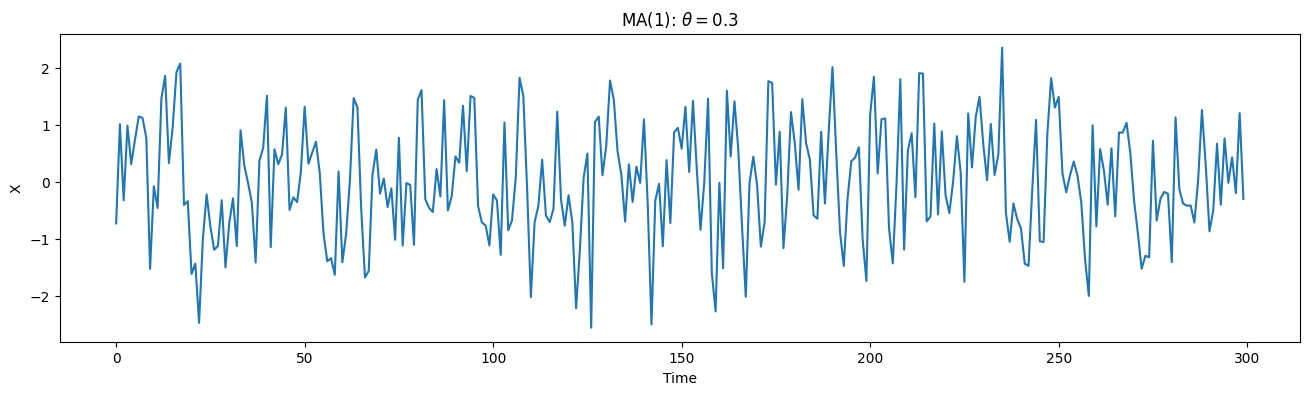

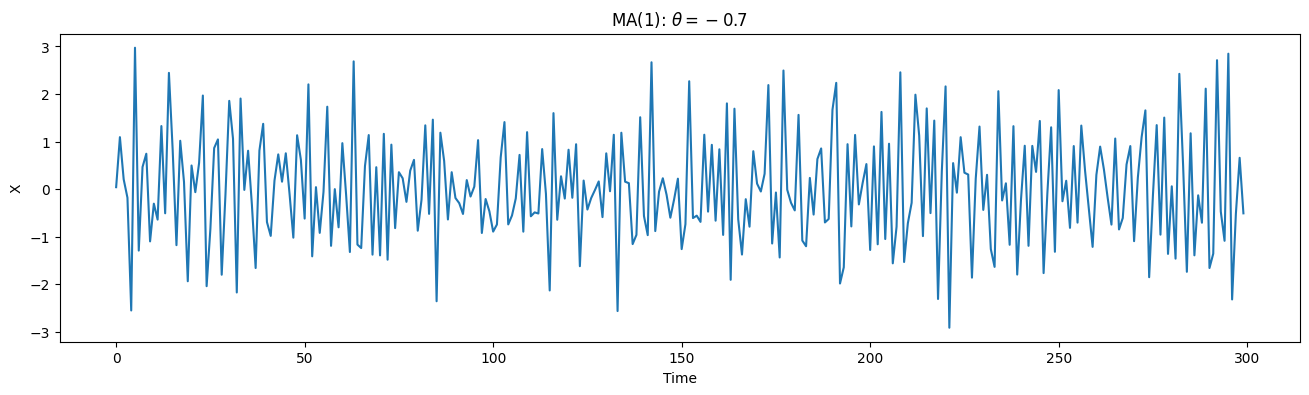

In [25]:
# Các ví dụ trung bình trượt


# Hàm hỗ trợ MA1
def MA1(theta):
    arparams = np.array([0.0])
    ar = np.r_[1, -arparams]
    maparams = np.array([theta])
    ma = np.r_[1, maparams]  # thêm độ trễ 0
    y = arma_generate_sample(ar, ma, nsample=300)
    return y


# MA(1): theta=0.3
plt.figure(figsize=(16, 4))
plt.plot(MA1(0.3))
plt.title("MA(1): $\\theta=0.3$")
plt.xlabel("Thời gian")
plt.ylabel("X")
plt.show()

# MA(1): theta=-0.7
plt.figure(figsize=(16, 4))
plt.plot(MA1(-0.7))
plt.title("MA(1): $\\theta=-0.7$")
plt.xlabel("Thời gian")
plt.ylabel("X")
plt.show()

Từ hình 9, ta thấy chuỗi thời gian ở đồ thị dưới biến động mạnh hơn chuỗi thời gian ở đồ thị trên. Bây giờ, hãy kiểm tra trung bình, tự hiệp phương sai và tự tương quan của quá trình MA(1).

Trung bình:

$$ E(X_{t}) = E(W_{t} + \theta W_{t-1})=0 $$

Tự hiệp phương sai:

$$ \gamma(h)= \begin{cases}
  (1+\theta^{2}) \sigma^{2}  & \text{ với }  h=0 \\
  \theta \sigma^{2}  &  \text{ với }  h=1 \\
  0  &  \text{ với }  h\gt 1 
\end{cases} $$

ACF:

$$ \rho(h)= \begin{cases}
  \frac{\theta}{(1+\theta^{2})}  &  \text{ với } h=1 \\
  0  &  \text{ với }  h \gt 1 
\end{cases} $$

Từ công thức trên, ta biết trung bình và tự hiệp phương sai của chuỗi thời gian MA độc lập với thời gian. Do đó, chuỗi thời gian MA là dừng. Hãy xem các biểu đồ ACF của MA(1).

**Hình 10: ACF của MA(1): $\theta = 0.3$ và MA(2): $\theta = -0.7$**

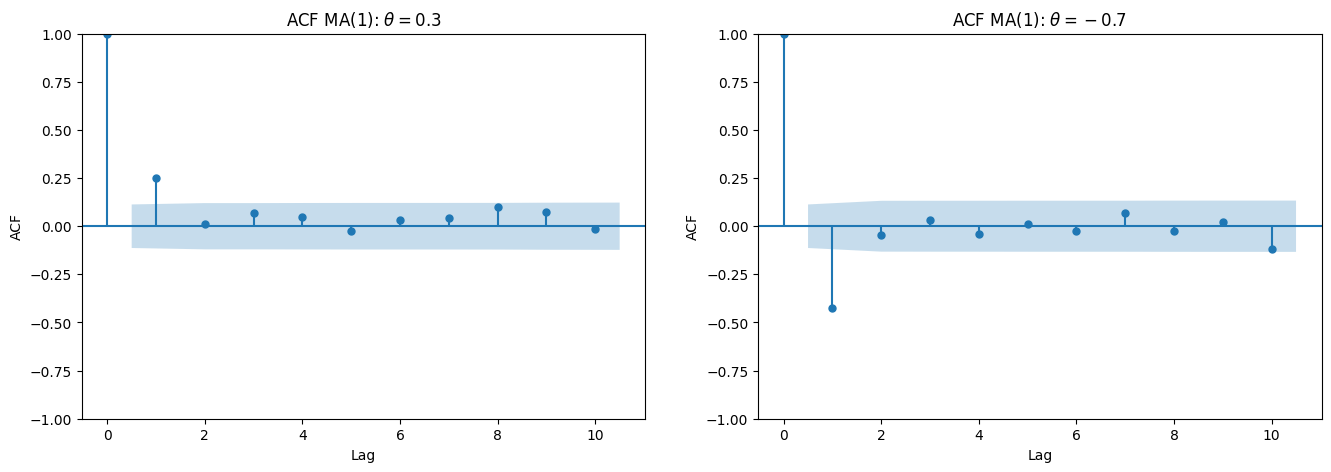

In [26]:
# ACF cho các ví dụ MA(1)
plt.figure(figsize=(16, 5))

# ACF cho MA(1): theta=0.3
ax1 = plt.subplot(121)
sm.graphics.tsa.plot_acf(MA1(0.3), title="ACF MA(1): $\\theta=0.3$", lags=10, ax=ax1)
plt.xlabel("Độ trễ")
plt.ylabel("ACF")

# ACF cho MA(1): theta=-0.7
ax2 = plt.subplot(122)
sm.graphics.tsa.plot_acf(MA1(-0.7), title="ACF MA(1): $\\theta=-0.7$", lags=10, ax=ax2)
plt.xlabel("Độ trễ")
plt.ylabel("ACF")
plt.show()

Từ hình 10, ta thấy các tự tương quan bằng $0$ sau độ trễ 1. Thực tế này cũng được phản ánh trong công thức tự hiệp phương sai và tự tương quan ở trên.

## **5. Ứng dụng của mô hình trung bình trượt**

Trong phần này, ta sẽ xây dựng một mô hình chuỗi thời gian cho giá cổ phiếu Google bằng mô hình MA(1). Trước tiên ta sẽ xây dựng một mô hình MA(1) bằng giá cổ phiếu Google gốc rồi sau đó ta sẽ xây dựng một mô hình MA(1) khác bằng sai phân bậc nhất của giá cổ phiếu Google.

### **5.1 Mô hình MA(1) với giá cổ phiếu Google gốc**

Hình 11 cho thấy kết quả mô hình MA(1) cho giá cổ phiếu Google gốc.

**Hình 11: Kết quả mô hình MA(1) cho giá cổ phiếu Google gốc**

In [27]:
# MA(1) cho cổ phiếu Google
goog_ma1 = statsmodels.tsa.arima.model.ARIMA(goog.GOOGLE, order=(0, 0, 1)).fit()
print(goog_ma1.params)

/usr/local/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:471: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:471: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:471: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


const      1327.669054
ma.L1         0.969844
sigma2    96592.222445
dtype: float64


Từ hình 11, ta thấy $\theta$ ước lượng là 0,9699 và hệ số chặn là 1327,617. Hãy xem mô hình khớp dữ liệu thực tế thế nào. Hình 12 cho thấy đồ thị so sánh giá cổ phiếu Google gốc và giá cổ phiếu khớp.

**Hình 12: Giá cổ phiếu Google gốc so với giá cổ phiếu Google khớp**

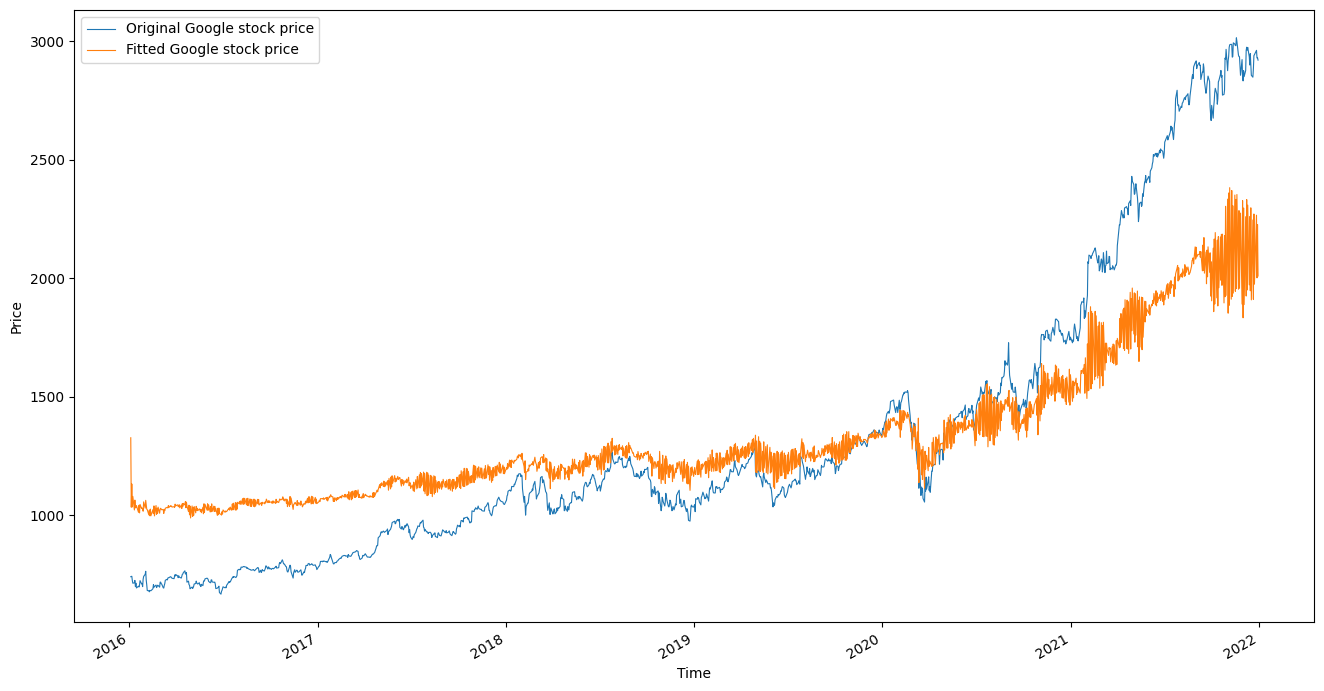

In [28]:
# Vẽ giá cổ phiếu Google so với giá khớp
goog_ma1_res = goog_ma1.resid
goog_ma1_fit = goog["GOOGLE"] - goog_ma1_res

goog["GOOGLE"].plot(linewidth=0.8, label="Giá cổ phiếu Google gốc")
goog_ma1_fit.plot(linewidth=0.8, label="Giá cổ phiếu Google khớp")
plt.xlabel("Thời gian")
plt.ylabel("Giá")
plt.legend()
plt.show()

Từ hình 12, ta thấy đường cong giá cổ phiếu Google khớp (màu cam) không bám sát đường cong giá cổ phiếu Google thực tế (màu xanh dương). Ta biết giá cổ phiếu Google gốc không dừng. Do đó, hãy thực hiện lấy sai phân bậc nhất của giá cổ phiếu gốc và kiểm tra chuỗi thời gian sai phân bậc nhất với mô hình MA(1) một lần nữa.

### **5.2 Mô hình MA(1) với sai phân bậc nhất của giá cổ phiếu Google**

**Hình 13: Kết quả mô hình MA(1) cho sai phân bậc nhất của giá cổ phiếu Google**

In [29]:
# MA(1) cho sai phân bậc nhất của giá cổ phiếu Google
goog_ma2 = statsmodels.tsa.arima.model.ARIMA(goog.GOOGLE, order=(0, 1, 1)).fit()
print(goog_ma2.params)

ma.L1      -0.078980
sigma2    532.948967
dtype: float64


/usr/local/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:471: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:471: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:471: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


Bây giờ ta thấy chúng ta chỉ có $\theta$ ước lượng = -0,07898 mà không có hệ số chặn. Đó là vì ta đang mô hình hóa sai phân bậc nhất. Hãy kiểm tra đồ thị thực tế so với dự báo.

**Hình 14: Giá cổ phiếu Google so với giá cổ phiếu Google khớp khi dùng sai phân bậc nhất**

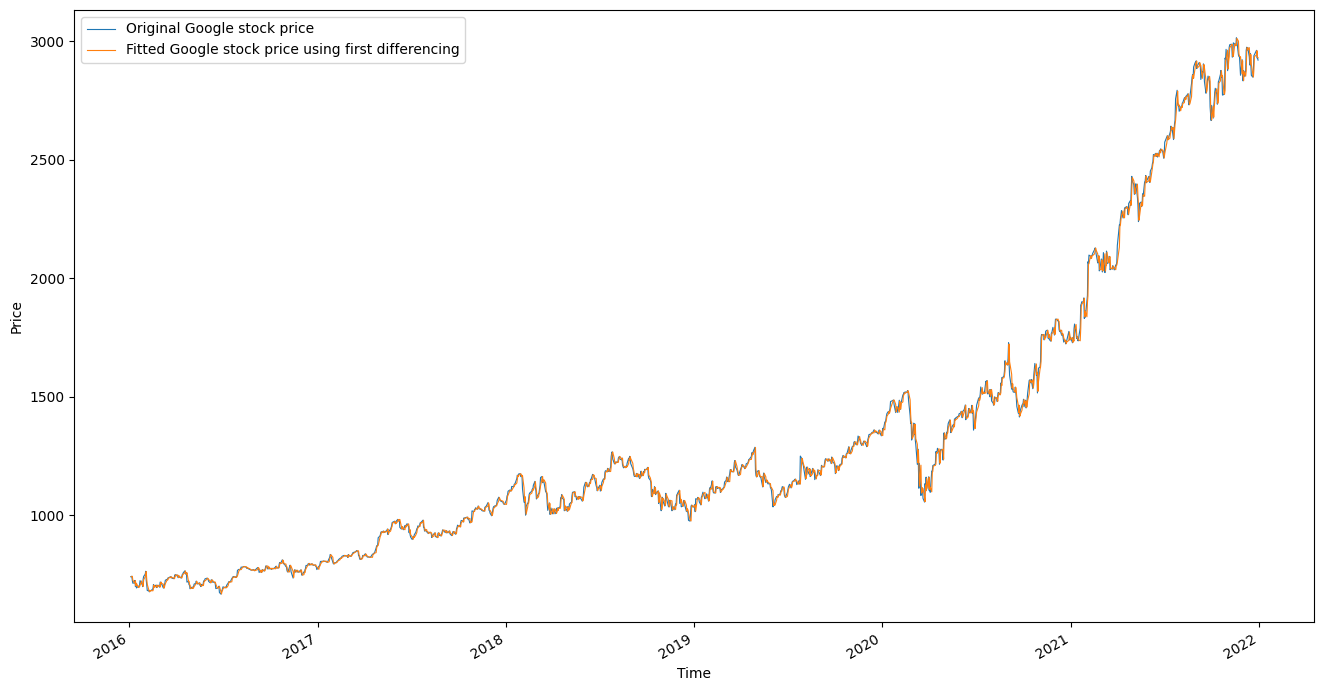

In [30]:
# Vẽ giá cổ phiếu Google so với giá khớp khi dùng sai phân bậc nhất
goog_ma2_res = goog_ma2.resid
goog_ma2_fit = goog["GOOGLE"] - goog_ma2_res

goog_ma2_res = goog_ma2_res[
    1:
]  # cần bỏ phần tử đầu tiên do mô hình mất một điểm dữ liệu
goog_ma2_fit = goog_ma2_fit[
    1:
]  # cần bỏ phần tử đầu tiên do mô hình mất một điểm dữ liệu

goog["GOOGLE"].plot(linewidth=0.8, label="Giá cổ phiếu Google gốc")
goog_ma2_fit.plot(
    linewidth=0.8, label="Giá cổ phiếu Google khớp khi dùng sai phân bậc nhất"
)
plt.xlabel("Thời gian")
plt.ylabel("Giá")
plt.legend()
plt.show()

Ta thấy từ hình 14 rằng lấy sai phân bậc nhất cho ra mô hình tốt hơn đáng kể so với bộ dữ liệu gốc. Nó cũng nêu bật tầm quan trọng của việc làm cho chuỗi thời gian dừng trước khi xác định mô hình cho phần dừng của chính nó.

## **6. Kết luận**

Trong bài này, trước tiên ta bàn về hai phương pháp loại bỏ xu hướng trong chuỗi thời gian. Phương pháp thứ nhất là đưa một biến xu hướng vào mô hình hồi quy đơn giản. Phương pháp thứ hai là dùng sai phân bậc nhất. Sau đó ta bắt đầu đi qua một số mô hình thống kê chuỗi thời gian. Ta nói về nhiễu trắng như số hạng sai số của chuỗi thời gian. Rồi, ta nói về bước ngẫu nhiên và bước ngẫu nhiên có độ trôi để mô hình hóa chuỗi thời gian không dừng. Sau đó ta giới thiệu mô hình trung bình trượt và áp dụng nó vào giá cổ phiếu Google. Ở bài tiếp theo, ta sẽ tiếp tục hành trình và học thêm các mô hình thống kê chuỗi thời gian.